# MNIST Autoencoder: Dimensionality Reduction and Reconstruction
 by Rohith John 
 (24BAD100)

# PART A: DATASET PREPARATION AND PREPROCESSING

In [1]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from tensorflow.keras import layers, Model

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU devices: []


2026-10-29 03:31:32.530626: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Load MNIST Dataset

In [2]:
# Automatically search Kaggle Input for a compatible MNIST CSV.
# If none is attached, use the built-in TensorFlow/Keras MNIST dataset.

def find_mnist_csv():
    paths = []
    for root, dirs, files in os.walk("/kaggle/input"):
        for name in files:
            if name.lower().endswith(".csv"):
                paths.append(os.path.join(root, name))

    paths.sort(key=lambda p: (
        0 if "mnist" in os.path.basename(p).lower() and "train" in os.path.basename(p).lower()
        else 1 if os.path.basename(p).lower() == "train.csv"
        else 2
    ))

    label_names = ["label", "Label", "target", "Target", "class", "Class"]

    for path in paths:
        try:
            preview = pd.read_csv(path, nrows=5)
            cols = list(preview.columns)
            label_col = next((c for c in label_names if c in cols), None)

            if label_col is not None:
                pixels = len(cols) - 1
            elif len(cols) == 785:
                label_col = cols[0]
                pixels = 784
            else:
                pixels = len(cols)

            if pixels == 784:
                return path, label_col
        except Exception as e:
            print("Skipping CSV:", path, "|", e)

    return None, None


CSV_PATH, LABEL_COL = find_mnist_csv()

if CSV_PATH:
    print("Using Kaggle CSV:", CSV_PATH)
    data = pd.read_csv(CSV_PATH)

    if LABEL_COL is not None:
        labels_all = data[LABEL_COL].to_numpy()
        pixels_df = data.drop(columns=[LABEL_COL])
    else:
        labels_all = None
        pixels_df = data

    X_all = pixels_df.to_numpy(dtype=np.float32)
    if X_all.shape[1] != 784:
        raise ValueError(f"Expected 784 pixel columns, found {X_all.shape[1]}.")

    if X_all.max() > 1.0:
        X_all /= 255.0
    X_all = np.clip(X_all, 0.0, 1.0)

    stratify = labels_all if labels_all is not None else None
    split_labels = labels_all if labels_all is not None else np.zeros(len(X_all))

    x_train, x_test, y_train, y_test = train_test_split(
        X_all, split_labels, test_size=0.20,
        random_state=SEED, stratify=stratify
    )

    if labels_all is None:
        y_train, y_test = None, None
    DATA_SOURCE = "Kaggle CSV"

else:
    print("No compatible Kaggle CSV found. Loading MNIST using Keras.")
    (x_train_img, y_train), (x_test_img, y_test) = tf.keras.datasets.mnist.load_data()
    x_train = x_train_img.reshape(-1, 784).astype("float32") / 255.0
    x_test = x_test_img.reshape(-1, 784).astype("float32") / 255.0
    DATA_SOURCE = "TensorFlow/Keras MNIST"

print("\nDataset source:", DATA_SOURCE)
print("Training shape:", x_train.shape)
print("Testing shape :", x_test.shape)


Using Kaggle CSV: /kaggle/input/datasets/oddrationale/mnist-in-csv/mnist_train.csv

Dataset source: Kaggle CSV
Training shape: (48000, 784)
Testing shape : (12000, 784)


## Dataset Exploration

Training images: 48000
Testing images : 12000
Original image size: 28 x 28
Flattened input dimension: 784
Pixel range: 0.0 to 1.0


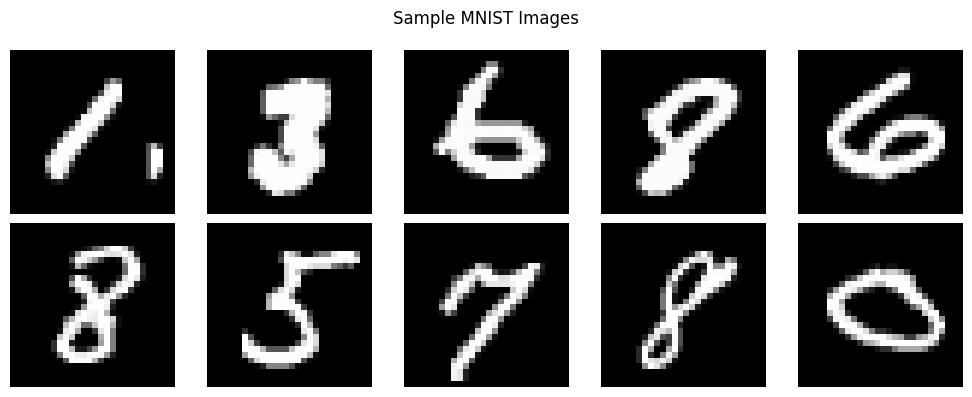

In [3]:
print("Training images:", len(x_train))
print("Testing images :", len(x_test))
print("Original image size: 28 x 28")
print("Flattened input dimension:", x_train.shape[1])
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))

samples = x_train[:10].reshape(-1, 28, 28)
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(samples[i], cmap="gray")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()


# PART B: IMPLEMENTING THE ENCODER AND DECODER

In [4]:
INPUT_DIM = 784
LATENT_DIM = 32

print("Input dimension:", INPUT_DIM)
print("Latent dimension:", LATENT_DIM)


Input dimension: 784
Latent dimension: 32


In [5]:
# Encoder

encoder_input = layers.Input(shape=(INPUT_DIM,), name="encoder_input")
x = layers.Dense(256, activation="relu")(encoder_input)
x = layers.Dense(128, activation="relu")(x)
latent_vector = layers.Dense(LATENT_DIM, activation="relu", name="latent_representation")(x)

encoder = Model(encoder_input, latent_vector, name="Encoder")
encoder.summary()


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (Dense)   │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,984 (929.62 KB)

 Trainable params: 237,984 (929.62 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Decoder

decoder_input = layers.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(128, activation="relu")(decoder_input)
x = layers.Dense(256, activation="relu")(x)
decoder_output = layers.Dense(INPUT_DIM, activation="sigmoid", name="reconstructed_output")(x)

decoder = Model(decoder_input, decoder_output, name="Decoder")
decoder.summary()


Model: "Decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_output (Dense)    │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,736 (932.56 KB)

 Trainable params: 238,736 (932.56 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Combined Autoencoder

autoencoder_input = layers.Input(shape=(INPUT_DIM,), name="autoencoder_input")
autoencoder_output = decoder(encoder(autoencoder_input))

autoencoder = Model(autoencoder_input, autoencoder_output, name="Autoencoder")
autoencoder.summary()


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       237,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       238,736 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 476,720 (1.82 MB)

 Trainable params: 476,720 (1.82 MB)

 Non-trainable params: 0 (0.00 B)

# PART C: COMPILING AND TRAINING THE AUTOENCODER

In [8]:
# Compile the autoencoder

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

print("Optimizer: Adam")
print("Reconstruction loss: Binary Cross-Entropy")


Optimizer: Adam
Reconstruction loss: Binary Cross-Entropy


In [9]:
# Train using the input images as both input and target

EPOCHS = 10
BATCH_SIZE = 256

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)


Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.2381 - val_loss: 0.1596
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.1413 - val_loss: 0.1275
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.1207 - val_loss: 0.1148
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.1117 - val_loss: 0.1084
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.1066 - val_loss: 0.1041
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.1029 - val_loss: 0.1011
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.1001 - val_loss: 0.0989
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0979 - val_loss: 0.0970
Epoch 9/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0960 - val_loss: 0.0952
Epoch 10/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0942 - val_loss: 0.0935


In [10]:
# Training history

history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "Epoch"
display(history_df.round(4))

print("Final training loss:", round(history.history["loss"][-1], 4))
print("Final validation loss:", round(history.history["val_loss"][-1], 4))


,loss,val_loss
Epoch,,
1,0.2381,0.1596
2,0.1413,0.1275
3,0.1207,0.1148
4,0.1117,0.1084
5,0.1066,0.1041
6,0.1029,0.1011
7,0.1001,0.0989
8,0.0979,0.0970
9,0.0960,0.0952


Final training loss: 0.0942
Final validation loss: 0.0935


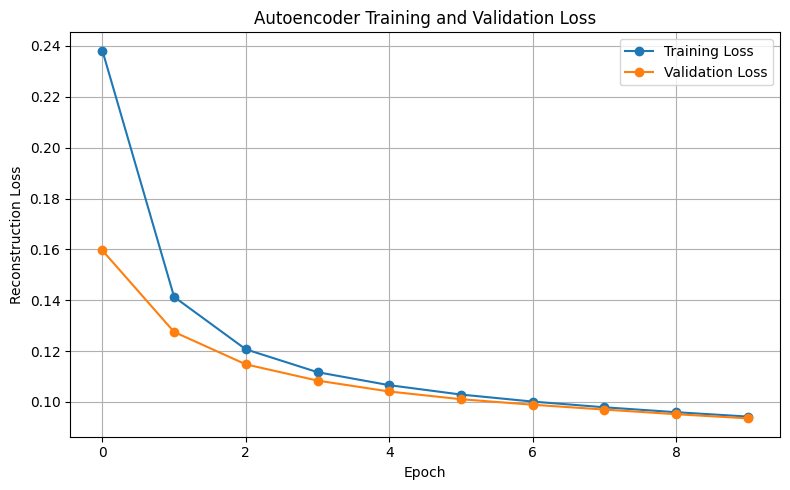

In [11]:
# Training and validation loss graph

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# PART D: DIMENSIONALITY REDUCTION, FEATURE LEARNING AND RECONSTRUCTION

In [12]:
# Evaluate reconstruction loss on test data

test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)
print("Test reconstruction loss:", round(float(test_loss), 4))


Test reconstruction loss: 0.0935


In [13]:
# Encode test images into latent vectors

latent_features = encoder.predict(x_test, batch_size=BATCH_SIZE, verbose=1)

print("Original input shape:", x_test.shape)
print("Original input dimension:", x_test.shape[1])
print("Latent feature shape:", latent_features.shape)
print("Latent dimension:", latent_features.shape[1])


47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Original input shape: (12000, 784)
Original input dimension: 784
Latent feature shape: (12000, 32)
Latent dimension: 32


In [14]:
# Reconstruct images using the decoder

reconstructed_images = decoder.predict(
    latent_features,
    batch_size=BATCH_SIZE,
    verbose=1
)

print("Reconstructed data shape:", reconstructed_images.shape)


47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Reconstructed data shape: (12000, 784)


## Original Images vs Reconstructed Images

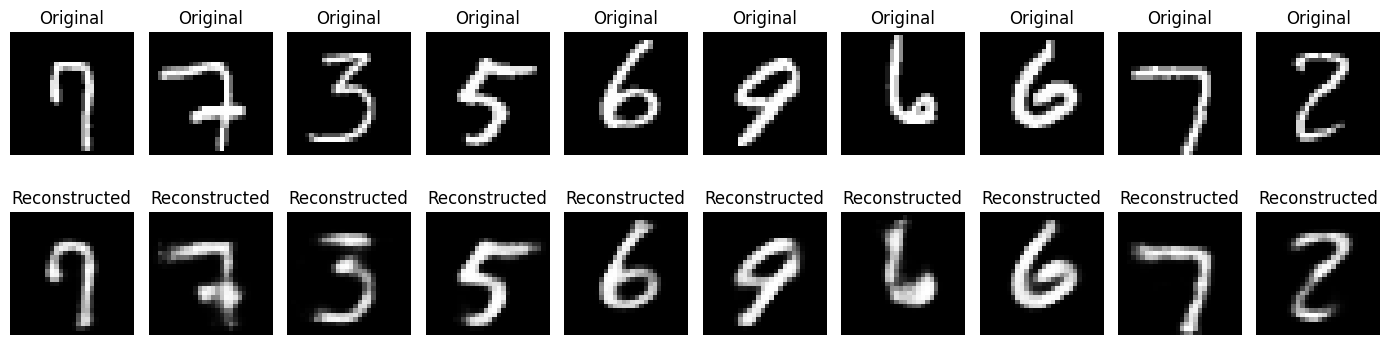

In [15]:
NUM_DISPLAY = 10

original_display = x_test[:NUM_DISPLAY].reshape(-1, 28, 28)
reconstructed_display = reconstructed_images[:NUM_DISPLAY].reshape(-1, 28, 28)

plt.figure(figsize=(14, 4))
for i in range(NUM_DISPLAY):
    plt.subplot(2, NUM_DISPLAY, i + 1)
    plt.imshow(original_display[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, NUM_DISPLAY, i + 1 + NUM_DISPLAY)
    plt.imshow(reconstructed_display[i], cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Latent Space Visualization using PCA

In [16]:
# Reduce selected latent vectors to two dimensions

NUM_PCA = min(5000, len(latent_features))
pca = PCA(n_components=2, random_state=SEED)
latent_2d = pca.fit_transform(latent_features[:NUM_PCA])

print("Latent input shape:", latent_features[:NUM_PCA].shape)
print("PCA output shape:", latent_2d.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)


Latent input shape: (5000, 32)
PCA output shape: (5000, 2)
Explained variance ratio: [0.30062342 0.10294563]


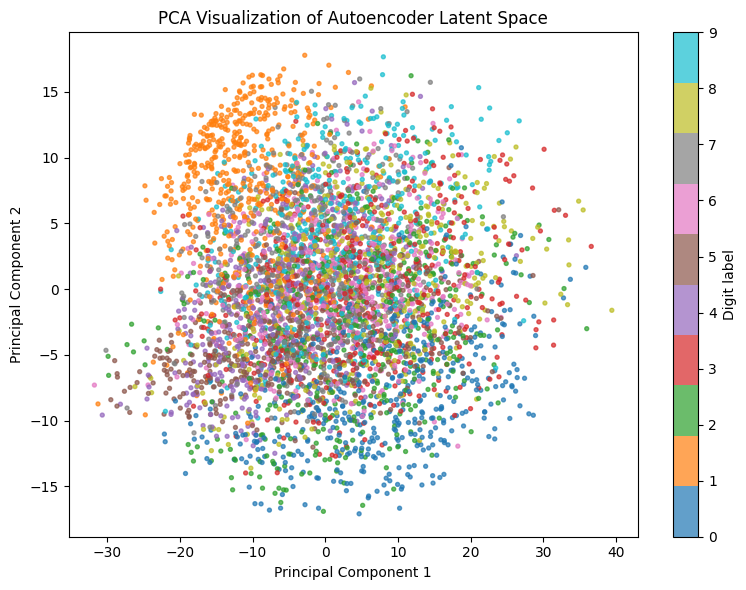

In [17]:
# Plot 2D PCA representation

plt.figure(figsize=(8, 6))
if y_test is not None:
    plt.scatter(
        latent_2d[:, 0], latent_2d[:, 1],
        c=y_test[:NUM_PCA], cmap="tab10", s=8, alpha=0.7
    )
    plt.colorbar(label="Digit label")
else:
    plt.scatter(latent_2d[:, 0], latent_2d[:, 1], s=8, alpha=0.7)

plt.title("PCA Visualization of Autoencoder Latent Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()


## Save Reconstructed Images

In [18]:
# Save reconstructed images in Kaggle Working

OUTPUT_DIR = "/kaggle/working/autoencoder_reconstructions"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for i, image in enumerate(reconstructed_display):
    image_uint8 = np.clip(image * 255, 0, 255).astype(np.uint8)
    tf.keras.utils.save_img(
        os.path.join(OUTPUT_DIR, f"reconstructed_{i + 1:02d}.png"),
        image_uint8[..., np.newaxis],
        scale=False
    )

print("Saved reconstructed images:", len(os.listdir(OUTPUT_DIR)))
print("Output directory:", OUTPUT_DIR)


Saved reconstructed images: 10
Output directory: /kaggle/working/autoencoder_reconstructions


In [19]:
# Save trained models and latent feature vectors

autoencoder.save("/kaggle/working/mnist_autoencoder.keras")
encoder.save("/kaggle/working/mnist_encoder.keras")
decoder.save("/kaggle/working/mnist_decoder.keras")
np.save("/kaggle/working/mnist_latent_features.npy", latent_features)

print("Saved autoencoder, encoder, decoder, and latent features in /kaggle/working/")


Saved autoencoder, encoder, decoder, and latent features in /kaggle/working/


# RESULT

The autoencoder was trained on MNIST images to learn a 32-dimensional latent representation from 784-dimensional inputs. The decoder reconstructed the test images, and reconstruction loss and visual comparisons were used to evaluate the model.